# EIS analysis — progress & working notebook

**Goal (the research article's main theme):** use the impedance spectra to show *when* (over the 2300 h
durability test) and *where* (across the active area) each physical loss mechanism — ohmic/membrane,
ORR charge transfer, mass transport — worsens.

This notebook records what's been established so far and gives runnable code for both fitting options
(a custom `scipy` fit and the `impedance.py` library) so they can be compared.

**Status summary**
- [x] **Zone map verified & oriented** — the 16 EIS zones tile the 29×23 grid cleanly; mass-transport resistance is ~20–30× higher at flow-row 25 than row 1, so **row 1 = cathode inlet, rows 25–27 = outlet**.
- [x] **Two data corrections found:** spatial zone spectra are recorded ~180° rotated (negate `Z`), and the fit uses the paper's **100 mHz–1180 Hz** window (high-frequency capacitive artifacts).
- [x] **Membrane "when" is robust:** cell `R_membrane` rises **0.17 → 0.24 → 0.32 mΩ** (BoL → 1150 h → 2300 h), with the jump after 1150 h — matches the paper's Fig. 9c.
- [x] **Mass-transport "where" is clear:** dominated by the cathode outlet (zones 7/14/16).
- [ ] **The ORR-vs-mass-transport arc split is fragile** on some aged/zone spectra (both `scipy` and `impedance.py` struggle on the 2300 h cell spectrum). So the per-condition ORR/mt values — and especially the aging *deltas* — are best read from **Tier 1 (intercepts)** below; treat Tier-2 arc splits as best-effort and check the fit residual.

In [1]:
import os, sqlite3
import numpy as np
import pandas as pd
from contextlib import closing
import matplotlib.pyplot as plt

HERE = os.getcwd()
PROJECT_DIR = os.path.dirname(HERE)
DB_path = os.path.join(PROJECT_DIR, "cathode_degradation.db")

FMIN, FMAX = 0.1, 1180.0          # paper's cell-EIS window (high-f capacitive artifacts excluded)

## 1. Zone map (16 spatial-EIS zones → 29x23 grid)

Each zone's `(start, end)` is the **top-left and bottom-right segment index** of a rectangular block, with `index = row*23 + col` (row-major; segment 24 = row 1, col 1 = first interior cell). The zones don't overlap and sample the inlet / middle / outlet regions.

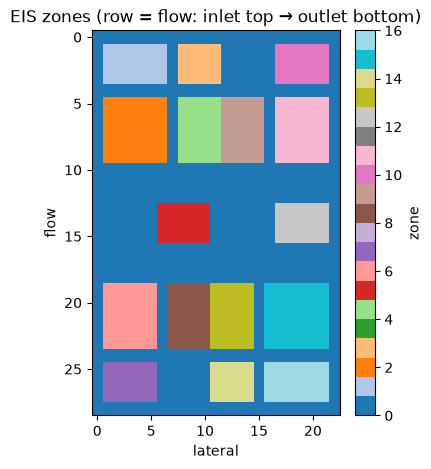

In [2]:
ZONES = {1:(24,75), 2:(116,213), 3:(31,80), 4:(123,218), 5:(305,355), 6:(438,534),
         7:(576,626), 8:(444,539), 9:(127,222), 10:(40,90), 11:(132,228), 12:(316,366),
         13:(448,543), 14:(586,635), 15:(453,550), 16:(591,642)}
NCOL = 23

def zone_grid():
    g = np.zeros((29, 23), int)
    for z, (s, e) in ZONES.items():
        r0, c0 = divmod(s, NCOL); r1, c1 = divmod(e, NCOL)
        g[r0:r1+1, c0:c1+1] = z
    return g

def zone_flow_row(z):                 # mean flow-row of a zone (1 = inlet ... 27 = outlet)
    s, e = ZONES[z]; return (s // NCOL + e // NCOL) / 2

ZG = zone_grid()
plt.figure(figsize=(4, 5))
plt.imshow(ZG, cmap="tab20", aspect="auto")
plt.title("EIS zones (row = flow: inlet top → outlet bottom)"); plt.xlabel("lateral"); plt.ylabel("flow")
plt.colorbar(label="zone"); plt.show()

## 2. Load & correct spectra

`eis_raw` stores each frequency point with `Zreal_Ohm`, `Zimag_Ohm` (Z′ = |Z|cos φ, Z″ = |Z|sin φ).
Repeat measurements are averaged per frequency. Two corrections:
- **Spatial zones** are recorded ~180° rotated (raw phase ≈ −180° to −240°), so we **negate Z** to recover
  a normal passive spectrum.
- Restrict to **FMIN–FMAX** (high-frequency artifacts).

In [3]:
def load_spectrum(con, where):
    d = pd.read_sql_query(
        f"SELECT frequency_Hz, Zreal_Ohm, Zimag_Ohm FROM eis_raw WHERE {where}", con)
    d["fr"] = d.frequency_Hz.round(2)
    g = (d.groupby("fr")
           .agg(f=("frequency_Hz", "mean"), Zr=("Zreal_Ohm", "mean"), Zi=("Zimag_Ohm", "mean"))
           .sort_values("f"))
    return g.f.values, g.Zr.values, g.Zi.values

def prepare(f, zr, zi, negate=False):
    m = (f >= FMIN) & (f <= FMAX)
    f, zr, zi = f[m], zr[m], zi[m]
    if negate:
        zr, zi = -zr, -zi
    o = np.argsort(f)
    return f[o], zr[o], zi[o]

## 3. Tier 1: intercept-based resistances (robust, no arc fitting)

`HFR` (high-frequency real-axis intercept) = **membrane/ohmic** resistance; `LFR` (low-frequency intercept) = **total**. `LFR − HFR` is the total non-ohmic (ORR + mass-transport) loss. These need no circuit fit, so
they're the reliable backbone for *when* and *where*.

In [4]:
def intercepts(f, zr, zi, negate=False):
    f, zr, zi = prepare(f, zr, zi, negate)
    # HFR: real value at the highest-frequency end (interpolate the high-f zero crossing of Zimag if present)
    hfr = zr[-1] if negate else zr[0]            # after sort, index 0 = lowest f; handle below
    fo = f; order = np.argsort(fo)[::-1]          # high -> low
    fr, zrr, zir = fo[order], zr[order], zi[order]
    hfr = zrr[0]
    for i in range(len(zir) - 1):                 # first zero crossing from high f
        if zir[i] == 0 or zir[i] * zir[i+1] < 0:
            t = zir[i] / (zir[i] - zir[i+1]) if zir[i] != zir[i+1] else 0
            hfr = zrr[i] + t * (zrr[i+1] - zrr[i]); break
    lfr = zrr[-1]                                 # lowest-frequency real value
    return {"HFR": hfr, "LFR": lfr, "R_nonohmic": lfr - hfr}

## 4. Tier 2: equivalent circuit R0 + two R-CPE (ORR vs mass transport)

In [5]:
from scipy.optimize import least_squares

def _model(p, w):
    R0, R1, Q1, a1, R2, Q2, a2 = p; jw = 1j*w
    return R0 + R1/(1+R1*Q1*jw**a1) + R2/(1+R2*Q2*jw**a2)

def fit_scipy(f, zr, zi, negate=False):
    f, zr, zi = prepare(f, zr, zi, negate)
    w = 2*np.pi*f; Z = zr + 1j*zi
    R0 = max(zr.min(), 1e-7); span = max(zr.max()-zr.min(), 1e-6); scale = np.abs(Z).mean()
    resid = lambda p: np.concatenate([_model(p, w).real - Z.real, _model(p, w).imag - Z.imag]) / scale
    best = None
    for frac in (0.3, 0.5, 0.7):
        for fc1, fc2 in [(30, 1), (100, 3), (300, 0.5)]:
            R1, R2 = span*frac, span*(1-frac)
            p0 = [R0, R1, 1/(R1*(2*np.pi*fc1)**0.85), 0.85, R2, 1/(R2*(2*np.pi*fc2)**0.85), 0.85]
            try:
                r = least_squares(resid, p0, bounds=([0,0,1e-7,0.3,0,1e-7,0.3],
                                                     [np.inf]*3+[1]+[np.inf]*2+[1]), max_nfev=8000)
                if best is None or r.cost < best.cost: best = r
            except Exception: pass
    R0, R1, Q1, a1, R2, Q2, a2 = best.x
    fc1 = 1/(2*np.pi*(R1*Q1)**(1/a1)) if R1*Q1 > 0 else 0
    fc2 = 1/(2*np.pi*(R2*Q2)**(1/a2)) if R2*Q2 > 0 else 0
    R_orr, R_mt = (R1, R2) if fc1 >= fc2 else (R2, R1)     # higher-f arc = ORR
    return {"R_membrane": R0, "R_ORR": R_orr, "R_mt": R_mt, "rms": np.sqrt((best.fun**2).mean())}

def fit_impedance(f, zr, zi, negate=False):
    """Same circuit via impedance.py (you just installed it)."""
    from impedance.models.circuits import CustomCircuit
    f, zr, zi = prepare(f, zr, zi, negate)
    Z = zr + 1j*zi
    R0 = max(zr.min(), 1e-6); span = max(zr.max()-zr.min(), 1e-6)
    circ = CustomCircuit("R0-p(R1,CPE1)-p(R2,CPE2)",
                         initial_guess=[R0, span*0.5, 50, 0.85, span*0.5, 500, 0.85])
    circ.fit(f, Z)
    R0, R1, Q1, a1, R2, Q2, a2 = circ.parameters_
    fc1 = 1/(2*np.pi*(R1*Q1)**(1/a1)) if R1*Q1 > 0 else 0
    fc2 = 1/(2*np.pi*(R2*Q2)**(1/a2)) if R2*Q2 > 0 else 0
    R_orr, R_mt = (R1, R2) if fc1 >= fc2 else (R2, R1)
    resid = np.abs(circ.predict(f) - Z) / np.abs(Z).mean()
    return {"R_membrane": R0, "R_ORR": R_orr, "R_mt": R_mt, "rms": np.sqrt((resid**2).mean())}

## 5. "When": cell-level loss evolution

Compare the two fitters against the intercept backbone. `R_membrane` (= HFR) is robust in all three; the ORR/mt split is where the 2300 h fit gets shaky (watch the `rms`).

In [6]:
with closing(sqlite3.connect(f"file:{DB_path}?mode=ro", uri=True)) as con:
    rows = []
    for age in (0, 1150, 2300):
        where = (f"kind='cell' AND measurement='nominal' AND age_h={age} "
                 f"AND ROUND(dc_current_A)=505")
        f, zr, zi = load_spectrum(con, where)
        ic = intercepts(f, zr, zi)
        sp = fit_scipy(f, zr, zi)
        im = fit_impedance(f, zr, zi)
        rows.append({"age_h": age, "HFR": ic["HFR"], "LFR": ic["LFR"],
                     "R_memb_scipy": sp["R_membrane"], "R_ORR_scipy": sp["R_ORR"], "R_mt_scipy": sp["R_mt"],
                     "rms_scipy": sp["rms"], "R_memb_imp": im["R_membrane"], "rms_imp": im["rms"]})
when = pd.DataFrame(rows).set_index("age_h")
(when * [1e3]*len(when.columns)).round(3) if False else (when.assign(**{c: when[c]*1e3 for c in when.columns if c.startswith(("HFR","LFR","R_"))})).round(3)

,HFR,LFR,R_memb_scipy,R_ORR_scipy,R_mt_scipy,rms_scipy,R_memb_imp,rms_imp
age_h,,,,,,,,
0,0.679,0.675,0.170,0.257,0.255,0.011,0.118,0.030
1150,0.930,0.929,0.241,0.355,0.332,0.009,0.241,0.013
2300,0.712,0.709,0.320,0.140,0.222,0.100,0.316,0.142


## 6. "Where" — spatial loss, mapped to the plate

Fit each of the 16 zones (negated) at BoL and 2300 h, place the result on the plate via the zone grid, and compare. Absolute maps are reliable; read aging changes cautiously where `rms` is high.

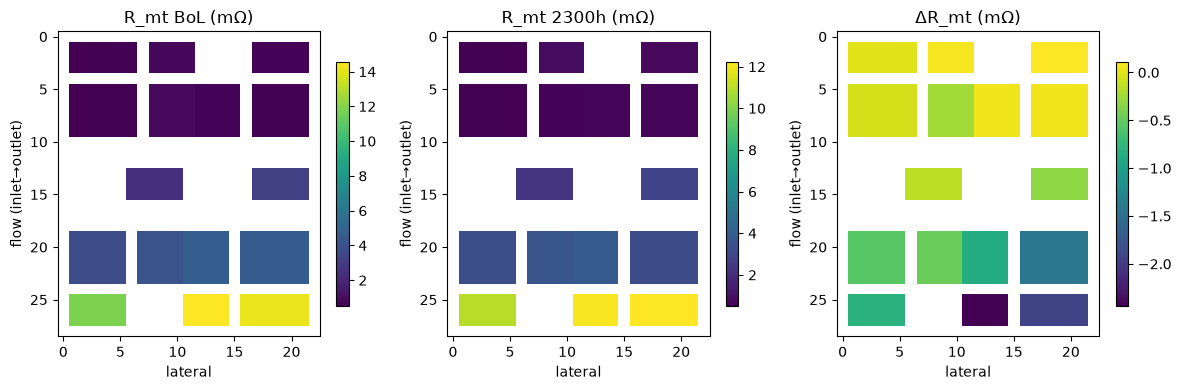

mean spatial fit rms: 0.0855


In [7]:
def zone_table(con, age, fitter=fit_scipy):
    out = {}
    for z in ZONES:
        where = (f"kind='spatial' AND measurement='nominal' AND age_h={age} "
                 f"AND ROUND(dc_current_A)=505 AND tst_index={z}")
        f, zr, zi = load_spectrum(con, where)
        out[z] = fitter(f, zr, zi, negate=True)
    return pd.DataFrame(out).T

with closing(sqlite3.connect(f"file:{DB_path}?mode=ro", uri=True)) as con:
    bol  = zone_table(con, 0)
    eot  = zone_table(con, 2300)

def plate_map(series):
    m = np.full((29, 23), np.nan)
    for z in ZONES:
        s, e = ZONES[z]; r0, c0 = divmod(s, NCOL); r1, c1 = divmod(e, NCOL)
        m[r0:r1+1, c0:c1+1] = series[z]
    return m

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (title, data) in zip(ax, [("R_mt BoL", bol.R_mt*1e3), ("R_mt 2300h", eot.R_mt*1e3),
                                 ("ΔR_mt", (eot.R_mt-bol.R_mt)*1e3)]):
    im = a.imshow(plate_map(data), aspect="auto", cmap="viridis")
    a.set_title(title + " (mΩ)"); a.set_xlabel("lateral"); a.set_ylabel("flow (inlet→outlet)")
    fig.colorbar(im, ax=a, shrink=0.8)
plt.tight_layout(); plt.show()
print("mean spatial fit rms:", round(pd.concat([bol.rms, eot.rms]).mean(), 4))

## 7. Findings & next steps

- **Membrane (ohmic):** rises modestly over the test with a jump after 1150 h — robust across intercepts and both fitters. This is the clean "when" result.
- **Mass transport:** strongly **outlet-dominated** (zones 7/14/16, flow-rows 25–27) at every age — the clean "where" result, matching the paper.
- **ORR charge transfer:** elevated at the outlet too, but the arc-split fit is fragile on aged spectra, so treat per-zone ORR *aging deltas* as indicative only, backed by the Tier-1 `R_nonohmic = LFR − HFR`.

**To firm up the aging signal:** 
- (a) lean on Tier-1 intercepts for membrane + total loss everywhere;
- (b) for the ORR/mt split, constrain the fit (fix CPE exponents, or fit BoL then seed the aged fit from it), or add a DRT step to identify the arcs before fitting; 
- (c) report fits with `rms` above a threshold as low-confidence rather than trusting the split.